# Murray Buttes | Terrain-aware route planning

This notebook compares routes between two points in a 1 m terrain grid of Murray Buttes, Gale crater. It is the computational part of our Marswalk planning prototype.

Method in brief: We use eight-neighbour Dijkstra search. The main objective is a slope-dependent walking-energy estimate based on the Minetti equation. We also compare distance minimisation and optional roughness / mapped-butte avoidance. The model is a research prototype, not an operational EVA safety tool.

### Running the notebook

1. Create the Python environment using `nasa-data-portable.yml`.
2. Arrange the project as shown below. The terrain CSV is required; the HiRISE TIFF is optional for plotting.
3. Open the notebook and run the cells from top to bottom. Adjust `START` and `GOAL` in the configuration cell.
4. Review the `results/` folder for route summaries, plots, cell coordinates, warnings and reproducibility metadata.


**Notes:** The CSV already contains derived slope, roughness, texture and mapped-geology fields; these are not regenerated here. Source imagery and its usage terms are described in the project README. The selected start/end cells must be valid unflagged terrain cells.


**Running the repository version:** `notebooks/` and `data/` should be sibling folders. The terrain CSV is required; the HiRISE TIFF is optional and only used to draw routes over the original imagery.


## 1. Imports


In [1]:
import json
import heapq
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter
import matplotlib
matplotlib.use("Agg")  
import matplotlib.pyplot as plt
from IPython.display import display, Image



## 2. Input locations and experiment settings

For a normal GitHub checkout, put the notebook in `notebooks/` and `Murray_Buttes_Terrain_Data.csv` in `data/`, both under the same project folder. The search also accepts the previous CSV name. The results folder is created automatically. All model parameters for a new run are collected below.

In [2]:
# The working directory may be the repository root or notebooks/.
# For GitHub, keep the notebook in notebooks/ and the CSV in data/.
# We also accept the older filenames and the original local data structure.
# Optionally set the MURRAY_PROJECT_DIR environment variable to the project directory.
import os

project_override = os.environ.get("MURRAY_PROJECT_DIR")
search_roots = ([Path(project_override).expanduser()] if project_override else [])
search_roots += [Path.cwd(), Path.cwd().parent, Path.cwd() / "routing-model",
                 Path.cwd().parent / "routing-model"]
search_roots = list(dict.fromkeys(p.resolve() for p in search_roots))

input_locations = [
    Path("data/Murray_Buttes_Terrain_Data.csv"),  # shared repository name
    Path("data/Master_Terrain_v3.csv"),          # original name
    Path("Murray_Buttes_Master_Data/Terrain/Master_Terrain_v3.csv"),
]
found = [(root, root / rel) for root in search_roots for rel in input_locations
         if (root / rel).is_file()]
if not found:
    searched = "\n".join(str(root / rel) for root in search_roots for rel in input_locations)
    raise FileNotFoundError(
        "Terrain CSV was not found. Put Murray_Buttes_Terrain_Data.csv in data/ "
        "or set MURRAY_PROJECT_DIR.\nLooked in:\n" + searched
    )
ROOT, MASTER_CSV = found[0]
OUTPUT_DIR = ROOT / "results"  # keep generated figures and tables separate from inputs

# The HiRISE overlay is optional; routing only requires the master CSV.
imagery_candidates = [ROOT / "data" / "Murray Buttes Imagery.tif",
                      ROOT / "QGIS_Files" / "Murray Buttes Imagery.tif"]
IMAGERY_TIF = next((p for p in imagery_candidates if p.is_file()), imagery_candidates[0])
print(f"Project directory: {ROOT}")
print(f"Terrain input: {MASTER_CSV}")
print(f"Results directory: {OUTPUT_DIR}")

START = (400, 80)  # (row, col)
GOAL = (100, 400)  # (row, col)
PROMPT_FOR_ENDPOINTS = False  # True -> interactive text entry each run

# Which comparison routes should also be calculated?
COMPARE_SHORTEST = True
COMPARE_ROUGHNESS_AVOIDANCE = True
COMPARE_BUTTE_AVOIDANCE = True
COMPARE_BOTH_AVOIDANCE = False

# Narrow, flagged artifact cells can use reconstructed elevation, never raw DEM.
# No original file is overwritten. To restore conservative blocking, set False.
ALLOW_RECONSTRUCTED_CROSSING = True
MAX_REPAIR_WIDTH_CELLS = 8
WARN_ON_RECONSTRUCTED_CROSSING = True

# Model / experiment settings
MASS_KG = 100.0          # illustrative walking system mass
MAX_ABS_GRADE = 0.45    # dimensionless ±45% grade, not a safety certification
ROUGHNESS_EXCLUDE_TOP_PERCENT = 10.0  # upper 10% of usable-cell roughness

# DEM-error sensitivity: post-routing ONLY
RUN_MONTE_CARLO = True
MC_SIMULATIONS = 200
MC_ERROR_SD_M = 0.02           # hypothetical elevation-error standard deviation
MC_CORRELATION_SIGMA_PX = 2.0 # Gaussian filter sigma in 1-m grid pixels
MC_SEED = 20261115

# Plot controls
SHOW_HIRISE_OVERLAY = True  # optional: requires rasterio + compatible metadata
DISPLAY_OUTPUT_IMAGES = True
SAVE_STEP_LEVEL_TABLE = True



Project directory: C:\Users\Admin\Downloads\Repository
Terrain input: C:\Users\Admin\Downloads\Repository\data\Murray_Buttes_Terrain_Data.csv
Results directory: C:\Users\Admin\Downloads\Repository\results


## 3. Read and check the master terrain grid

In [3]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if not MASTER_CSV.is_file():
    raise FileNotFoundError(f"Master terrain CSV not found:\n{MASTER_CSV}")

cols = ["row", "col", "x_mars", "y_mars", "elevation_m",
        "slope_deg", "roughness_m", "valid_terrain", "artifact_suspected",
        "inside_butte", "butte_id", "red_mean", "green_mean", "blue_mean",
        "texture_mean", "texture_max", "themis_qualitative"]
df = pd.read_csv(MASTER_CSV, usecols=cols, dtype={"butte_id": "string"})
H, W = 499, 498
assert len(df) == H * W, f"Expected {H*W} grid records, got {len(df)}"
assert np.array_equal(df["row"].to_numpy(), np.repeat(np.arange(H), W)), "Unexpected CSV row order"
assert np.array_equal(df["col"].to_numpy(), np.tile(np.arange(W), H)), "Unexpected CSV col order"

def grid(key):
    return df[key].to_numpy().reshape(H, W)

def as_bool(key):
    return df[key].fillna(False).astype(bool).to_numpy().reshape(H, W)

z = grid("elevation_m").astype(float)
rough = grid("roughness_m").astype(float)
xmap = grid("x_mars").astype(float)
ymap = grid("y_mars").astype(float)
valid_terrain = as_bool("valid_terrain")
artifact = as_bool("artifact_suspected")  # IMPORTANT: existing, saved artifact marker
inside_butte = as_bool("inside_butte")
butte_id = grid("butte_id")
texture = grid("texture_mean").astype(float)
texture_max = grid("texture_max").astype(float)
red = grid("red_mean").astype(float)
green = grid("green_mean").astype(float)
blue = grid("blue_mean").astype(float)
brightness = np.nanmean(np.stack([red, green, blue]), axis=0)



## 4. Suspected DEM artifact: reconstruction

In [4]:
# ARTIFACT RECONSTRUCTION: row-wise linear interpolation across
# SHORT contiguous flagged gaps with valid anchors on BOTH sides.
# The output is an inferred surface, NOT observed terrain.
# Long/unbracketed gaps remain forbidden. The raw v3 DEM is intact.
# -------------------------------------------------------------
z_original = z.copy()
reconstructed = np.zeros((H,W), dtype=bool)
if ALLOW_RECONSTRUCTED_CROSSING:
    for r in range(H):
        indices = np.flatnonzero(artifact[r])
        if not indices.size:
            continue
        runs = np.split(indices, np.where(np.diff(indices) > 1)[0] + 1)
        for run in runs:
            left, right = int(run[0]) - 1, int(run[-1]) + 1
            if (len(run) > MAX_REPAIR_WIDTH_CELLS
                or left < 0 or right >= W
                or artifact[r,left] or artifact[r,right]
                or not (valid_terrain[r,left] and valid_terrain[r,right])
                or not (np.isfinite(z_original[r,left]) and np.isfinite(z_original[r,right]))):
                continue
            z[r,run] = np.interp(run, [left,right],
                                  [z_original[r,left],z_original[r,right]])
            reconstructed[r,run] = True

# Original DEM invalid cells remain prohibited, except the specifically
# reconstructed cells (which still carry their artifact flag).
usable = ((valid_terrain & ~artifact & np.isfinite(z))
          | (reconstructed & np.isfinite(z)))
rough_reference = rough[usable & ~artifact & np.isfinite(rough)]
texture_reference = texture[usable & ~artifact & np.isfinite(texture)]
if not len(rough_reference) or not len(texture_reference):
    raise ValueError("Roughness or texture reference measurements are unavailable.")
rough_threshold = np.percentile(rough_reference, 100 - ROUGHNESS_EXCLUDE_TOP_PERCENT)
texture_threshold = np.percentile(texture_reference, 90)

# Audit the original flagged cells and the subset reconstructed.
print("=== DATA CHECK ===")
print(f"Grid: {H} × {W} = {H*W:,} cells")
print(f"Usable including reconstructed cells: {usable.sum():,}")
print(f"Reconstructed artifact cells: {reconstructed.sum():,}; still blocked: {(artifact & ~reconstructed).sum():,}")
print(f"Flagged suspected DEM artifact cells: {artifact.sum():,}")
print(f"Roughness cutoff (upper {ROUGHNESS_EXCLUDE_TOP_PERCENT:g}%): {rough_threshold:.5f} m")
print(f"HiRISE texture p90: {texture_threshold:.4f}")



=== DATA CHECK ===
Grid: 499 × 498 = 248,502 cells
Usable including reconstructed cells: 245,520
Reconstructed artifact cells: 1,550; still blocked: 3
Flagged suspected DEM artifact cells: 1,553
Roughness cutoff (upper 10%): 0.03025 m
HiRISE texture p90: 42.0755


## 5. Choose start and destination

In [5]:
def parse_cell(text, default):
    if not text.strip():
        return default
    parts = text.replace("(", "").replace(")", "").replace(" ", "").split(",")
    if len(parts) != 2:
        raise ValueError("Enter row,col — for example 400,80")
    return (int(parts[0]), int(parts[1]))

if PROMPT_FOR_ENDPOINTS:
    START = parse_cell(input(f"Start row,col [{START[0]},{START[1]}]: "), START)
    GOAL = parse_cell(input(f"Goal row,col [{GOAL[0]},{GOAL[1]}]: "), GOAL)

START, GOAL = tuple(map(int, START)), tuple(map(int, GOAL))
for label, point in [("START", START), ("GOAL", GOAL)]:
    r, c = point
    if not (0 <= r < H and 0 <= c < W):
        raise ValueError(f"{label}={point} is outside the {H}×{W} grid")
    if artifact[r,c]:
        raise ValueError(f"{label}={point} lies on an inferred/flagged artifact cell. Choose an unflagged endpoint.")
    if not usable[r, c]:
        eligible = np.argwhere(usable & ~artifact)
        nearest = eligible[np.argmin(np.sum((eligible - np.array(point))**2, axis=1))]
        raise ValueError(f"{label}={point} is invalid or artifact-flagged. Nearby usable cell: {tuple(nearest)}. "
                         "Choose it explicitly if appropriate; endpoints are never silently moved.")
if START == GOAL:
    raise ValueError("Start and destination must differ.")
print(f"\nStart {START}: ({xmap[START]:.3f}, {ymap[START]:.3f}) projected Mars coordinates")
print(f"Goal  {GOAL}: ({xmap[GOAL]:.3f}, {ymap[GOAL]:.3f}) projected Mars coordinates")




Start (400, 80): (8141388.500, -278457.500) projected Mars coordinates
Goal  (100, 400): (8141708.500, -278157.500) projected Mars coordinates


## 6. Walking-energy model and terrain restrictions

In [6]:
# Signed grade s = (elevation destination - elevation source) / step length.
# C_M(0)=2.5; coefficients represent an empirical Earth walking model.
# These reference-scale energies must not be called validated Mars EVA needs.
def minetti_specific_cost(s):
    return (280.5*s**5 - 58.7*s**4 - 76.8*s**3
            + 51.9*s**2 + 19.6*s + 2.5)

def step_energy(s, distance_m):
    return MASS_KG * distance_m * minetti_specific_cost(s)

DIRECTIONS = {
    "N": (-1,0), "NE": (-1,1), "E": (0,1), "SE": (1,1),
    "S": (1,0), "SW": (1,-1), "W": (0,-1), "NW": (-1,-1)
}
NAME_BY_OFFSET = {v:k for k,v in DIRECTIONS.items()}

energy_maps, distance_maps, edge_slices = {}, {}, {}
for name, (dr, dc) in DIRECTIONS.items():
    r0, r1 = max(0, -dr), min(H, H-dr)
    c0, c1 = max(0, -dc), min(W, W-dc)
    src = np.s_[r0:r1, c0:c1]
    dst = np.s_[r0+dr:r1+dr, c0+dc:c1+dc]
    length = float(np.hypot(dr, dc))
    with np.errstate(invalid="ignore", over="ignore"):
        grade = (z[dst] - z[src]) / length
        cost = step_energy(grade, length)
    permitted = (usable[src] & usable[dst] & np.isfinite(grade)
                 & (np.abs(grade) <= MAX_ABS_GRADE)
                 & np.isfinite(cost) & (cost > 0))
    earr = np.full((H,W), np.nan, dtype=np.float32)
    darr = np.full((H,W), np.nan, dtype=np.float32)
    earr[src][permitted] = cost[permitted]
    darr[src][permitted] = length
    energy_maps[name] = earr
    distance_maps[name] = darr
    edge_slices[name] = (src, dst)

# Restriction mode: optional separate comparisons; baseline does NOT ban buttes.
def constrained_maps(maps, cell_allowed):
    out = {}
    for name in DIRECTIONS:
        src, dst = edge_slices[name]
        result = maps[name].copy()
        view = result[src]
        view[~(cell_allowed[src] & cell_allowed[dst])] = np.nan
        out[name] = result
    return out



## 7. Dijkstra route search

Compute the baseline minimum-energy route and feasible alternatives. Eight-neighbour moves are allowed, but diagonal corner-cutting past blocked cells is not.


In [7]:
def dijkstra(cost_maps, start, goal):
    distances = np.full((H,W), np.inf, dtype=np.float64)
    parent = np.full((H,W,2), -1, dtype=np.int32)
    distances[start] = 0.0
    pq = [(0.0, start[0], start[1])]
    while pq:
        best, r, c = heapq.heappop(pq)
        if best > distances[r,c]:
            continue
        if (r,c) == goal:
            break
        for name, (dr,dc) in DIRECTIONS.items():
            nr,nc = r+dr,c+dc
            if not (0 <= nr < H and 0 <= nc < W):
                continue
            cost = cost_maps[name][r,c]
            if not np.isfinite(cost):
                continue
            if dr and dc:
                vertical = "S" if dr > 0 else "N"
                horizontal = "E" if dc > 0 else "W"
                if not (np.isfinite(cost_maps[vertical][r,c])
                        and np.isfinite(cost_maps[horizontal][r,c])):
                    continue
            trial = best + float(cost)
            if trial < distances[nr,nc]:
                distances[nr,nc] = trial
                parent[nr,nc] = (r,c)
                heapq.heappush(pq, (trial,nr,nc))
    if not np.isfinite(distances[goal]):
        return None
    path = [goal]
    current = goal
    while current != start:
        r,c = current
        prev = tuple(parent[r,c])
        if prev[0] < 0:
            raise RuntimeError("Broken Dijkstra backtrack")
        path.append(prev)
        current = prev
    return path[::-1]

strategies = {"Minimum energy": energy_maps}
if COMPARE_SHORTEST:
    strategies["Shortest distance"] = distance_maps
if COMPARE_ROUGHNESS_AVOIDANCE:
    strategies["Avoid roughest 10%"] = constrained_maps(
        energy_maps, usable & (reconstructed | (np.isfinite(rough) & (rough <= rough_threshold))))
if COMPARE_BUTTE_AVOIDANCE:
    strategies["Avoid mapped buttes"] = constrained_maps(energy_maps, usable & ~inside_butte)
if COMPARE_BOTH_AVOIDANCE:
    strategies["Avoid roughness and buttes"] = constrained_maps(
        energy_maps, usable & (reconstructed | (np.isfinite(rough) & (rough <= rough_threshold))) & ~inside_butte)

routes, infeasible = {}, []
print("\n=== OPTIMIZING ROUTES ===")
for label, maps in strategies.items():
    route = dijkstra(maps, START, GOAL)
    if route is None:
        infeasible.append(label)
        print(f"{label}: NO FEASIBLE ROUTE under its constraints")
    else:
        routes[label] = route
        print(f"{label}: {len(route)} cells")
if "Minimum energy" not in routes:
    raise RuntimeError("No nominal energy-optimal route exists between these endpoints. "
                       "Try a pair connected by permitted terrain; no unsafe shortcut is introduced.")




=== OPTIMIZING ROUTES ===
Minimum energy: 369 cells
Shortest distance: 343 cells
Avoid roughest 10%: 444 cells
Avoid mapped buttes: 369 cells


## 8. Route statistics

Summarise length, elevation change, walking-energy estimate and descriptive terrain measurements for each returned route.


In [8]:
def route_geometry(route):
    p = np.asarray(route, dtype=np.int32)
    src, dst = p[:-1], p[1:]
    steps = np.hypot(dst[:,0]-src[:,0], dst[:,1]-src[:,1])
    return p, src, dst, steps

def weighted_edge_mean(array2d, src, dst, lengths):
    a = array2d[src[:,0],src[:,1]].astype(float)
    b = array2d[dst[:,0],dst[:,1]].astype(float)
    vals = (a+b)/2
    ok = np.isfinite(vals)
    return float(np.average(vals[ok],weights=lengths[ok])) if ok.any() else np.nan

route_summary, route_steps, route_cells, geometries = [], [], [], {}
for label, route in routes.items():
    p, src, dst, lengths = route_geometry(route)
    geometries[label] = (src, dst, lengths)
    delta_z = z[dst[:,0], dst[:,1]] - z[src[:,0], src[:,1]]
    grade = delta_z / lengths
    energy = step_energy(grade,lengths)
    if (not np.isfinite(energy).all() or not (np.abs(grade) <= MAX_ABS_GRADE+1e-10).all()
            or np.any(artifact[p[:,0],p[:,1]] & ~reconstructed[p[:,0],p[:,1]])
            or np.any(~usable[p[:,0],p[:,1]])):
        raise RuntimeError(f"Route {label} violates a baseline terrain consistency check")
    route_rough = rough[p[:,0],p[:,1]]
    route_tex = texture[p[:,0],p[:,1]]
    high_rough = (rough[src[:,0],src[:,1]] + rough[dst[:,0],dst[:,1]])/2 > rough_threshold
    high_tex = (texture[src[:,0],src[:,1]] + texture[dst[:,0],dst[:,1]])/2 > texture_threshold
    high_rough_valid = np.isfinite(rough[src[:,0],src[:,1]]) & np.isfinite(rough[dst[:,0],dst[:,1]])
    high_tex_valid = np.isfinite(texture[src[:,0],src[:,1]]) & np.isfinite(texture[dst[:,0],dst[:,1]])
    # Approximate distance within mapped polygons using segment midpoint membership.
    butte_length = float(np.sum(lengths * (inside_butte[src[:,0],src[:,1]]
                                           .astype(float) + inside_butte[dst[:,0],dst[:,1]].astype(float))/2))
    ids = sorted({str(v) for v in butte_id[p[:,0],p[:,1]]
                  if pd.notna(v) and str(v).strip() and str(v).lower() != "<na>"})
    route_summary.append({
        "Strategy":label, "Distance_m":float(lengths.sum()),
        "Minetti_reference_energy_J":float(energy.sum()),
        "Minetti_reference_energy_kJ":float(energy.sum()/1000),
        "Total_uphill_m":float(np.clip(delta_z,0,None).sum()),
        "Total_downhill_m":float(-np.clip(delta_z,None,0).sum()),
        "Net_elevation_change_m":float(delta_z.sum()),
        "Mean_abs_grade_pct":float(np.average(np.abs(grade),weights=lengths)*100),
        "Maximum_abs_grade_pct":float(np.max(np.abs(grade))*100),
        "Mean_roughness_m":weighted_edge_mean(rough,src,dst,lengths),
        "High_roughness_length_pct":float(100*lengths[high_rough & high_rough_valid].sum()/lengths[high_rough_valid].sum()) if high_rough_valid.any() else np.nan,
        "Approx_butte_distance_m":butte_length,
        "Butte_names":", ".join(ids) if ids else "None",
        "Mean_HiRISE_brightness":weighted_edge_mean(brightness,src,dst,lengths),
        "Mean_HiRISE_red":weighted_edge_mean(red,src,dst,lengths),
        "Mean_HiRISE_green":weighted_edge_mean(green,src,dst,lengths),
        "Mean_HiRISE_blue":weighted_edge_mean(blue,src,dst,lengths),
        "Mean_HiRISE_texture":weighted_edge_mean(texture,src,dst,lengths),
        "Mean_HiRISE_texture_max":weighted_edge_mean(texture_max,src,dst,lengths),
        "High_texture_length_pct":float(100*lengths[high_tex & high_tex_valid].sum()/lengths[high_tex_valid].sum()) if high_tex_valid.any() else np.nan,
        "Number_of_cells":len(route),
        "Flagged_artifact_cells":int(artifact[p[:,0],p[:,1]].sum()),
        "Reconstructed_elevation_cells":int(reconstructed[p[:,0],p[:,1]].sum()),
        "Approx_reconstructed_distance_m":float(np.sum(lengths * (
            reconstructed[src[:,0],src[:,1]].astype(float)
            + reconstructed[dst[:,0],dst[:,1]].astype(float))/2))})
    for i,(r,c) in enumerate(route):
        route_cells.append({"Strategy":label,"Step":i,"row":int(r),"col":int(c),
                            "x_mars":float(xmap[r,c]),"y_mars":float(ymap[r,c]),
                            "elevation_m":float(z[r,c]),"roughness_m":float(rough[r,c]) if np.isfinite(rough[r,c]) else np.nan,
                            "inside_butte":bool(inside_butte[r,c]),
                            "butte_id":str(butte_id[r,c]) if pd.notna(butte_id[r,c]) else "",
                            "brightness":float(brightness[r,c]) if np.isfinite(brightness[r,c]) else np.nan,
                            "texture_mean":float(texture[r,c]) if np.isfinite(texture[r,c]) else np.nan,
                            "artifact_suspected":bool(artifact[r,c]),
                            "elevation_reconstructed":bool(reconstructed[r,c]),
                            "original_elevation_m":float(z_original[r,c]) if np.isfinite(z_original[r,c]) else np.nan})
    if SAVE_STEP_LEVEL_TABLE:
        for i in range(len(lengths)):
            route_steps.append({"Strategy":label,"Move":i+1,
                                "from_row":int(src[i,0]),"from_col":int(src[i,1]),
                                "to_row":int(dst[i,0]),"to_col":int(dst[i,1]),
                                "movement_length_m":float(lengths[i]),
                                "elevation_change_m":float(delta_z[i]),
                                "signed_grade_pct":float(100*grade[i]),
                                "Minetti_reference_energy_J":float(energy[i]),
                                "uses_reconstructed_elevation":bool(reconstructed[src[i,0],src[i,1]] or reconstructed[dst[i,0],dst[i,1]])})


## 9. Warnings for routes crossing reconstructed cells

Warnings are generated **per route**. They identify the reconstructed cells visited and the approximate length of the crossing; the app can consume the exported JSON.


In [9]:
# Route-specific warning fields for the web app and human-readable report.
# These cells are estimated from neighboring DEM elevations, not ground-truth terrain.
ARTIFACT_WARNING = (
    "CAUTION: This route crosses interpolated elevations in a suspected DEM "
    "artifact corridor. Ground conditions and traversability are unverified."
)
summary = pd.DataFrame(route_summary)
summary["has_reconstructed_crossing"] = summary["Reconstructed_elevation_cells"].gt(0)
summary["warning_level"] = np.where(summary["has_reconstructed_crossing"], "caution", "none")
summary["warning_message"] = np.where(summary["has_reconstructed_crossing"], ARTIFACT_WARNING, "")
route_warnings = []
for label, route in routes.items():
    warning_row = summary.loc[summary["Strategy"] == label].iloc[0]
    crossing_cells = [
        {"row": int(r), "col": int(c),
         "x_mars": float(xmap[r,c]), "y_mars": float(ymap[r,c])}
        for r,c in route if reconstructed[r,c]
    ]
    route_warnings.append({
        "strategy": label,
        "has_warning": bool(warning_row["has_reconstructed_crossing"]),
        "severity": str(warning_row["warning_level"]),
        "message": str(warning_row["warning_message"]),
        "reconstructed_cells_crossed": int(warning_row["Reconstructed_elevation_cells"]),
        "approx_reconstructed_distance_m": float(warning_row["Approx_reconstructed_distance_m"]),
        "crossing_cells": crossing_cells
    })
primary_energy = float(summary.loc[summary.Strategy=="Minimum energy", "Minetti_reference_energy_J"].iloc[0])
summary["Extra_energy_vs_minimum_pct"] = 100*(summary["Minetti_reference_energy_J"]/primary_energy-1)
print("\n=== ROUTE COMPARISON (Minetti reference energy, not prior hybrid kJ) ===")
print(summary[["Strategy","Distance_m","Minetti_reference_energy_kJ",
               "Extra_energy_vs_minimum_pct","Maximum_abs_grade_pct",
               "Mean_roughness_m","Approx_butte_distance_m",
               "Mean_HiRISE_brightness","Mean_HiRISE_texture","High_texture_length_pct",
               "Reconstructed_elevation_cells","Approx_reconstructed_distance_m"]].round(3).to_string(index=False))
if WARN_ON_RECONSTRUCTED_CROSSING:
    for warning in route_warnings:
        if warning["has_warning"]:
            print("\n⚠ ARTIFACT CROSSING — " + warning["strategy"])
            print("  " + warning["message"])
            print("  Reconstructed cells: " + str(warning["reconstructed_cells_crossed"]))
            print("  Approximate affected route distance: "
                  + f'{warning["approx_reconstructed_distance_m"]:.2f} m')
            print("  Grid coordinates: " + str([(q["row"],q["col"]) for q in warning["crossing_cells"]]))




=== ROUTE COMPARISON (Minetti reference energy, not prior hybrid kJ) ===
           Strategy  Distance_m  Minetti_reference_energy_kJ  Extra_energy_vs_minimum_pct  Maximum_abs_grade_pct  Mean_roughness_m  Approx_butte_distance_m  Mean_HiRISE_brightness  Mean_HiRISE_texture  High_texture_length_pct  Reconstructed_elevation_cells  Approx_reconstructed_distance_m
     Minimum energy     473.210                      152.629                        0.000                 35.600             0.015                    0.000                  85.702               23.970                    3.149                              3                            4.243
  Shortest distance     457.151                      167.841                        9.967                 44.972             0.019                    0.000                  91.813               23.069                    2.784                              3                            4.243
 Avoid roughest 10%     532.056                      164

## 10. Monte Carlo sensitivity analysis (optional)

We perturb the DEM under a hypothetical error model, then recalculate energy **along each existing path**. This does not re-optimise routes or estimate a verified probability of safety.


In [10]:
mc_raw = []
mc_rows = []
if RUN_MONTE_CARLO:
    rng = np.random.default_rng(MC_SEED)
    print(f"\n=== POST-ROUTE MONTE CARLO: {MC_SIMULATIONS} DEM realizations ===")
    for it in range(MC_SIMULATIONS):
        noise = rng.normal(0,1,size=(H,W))
        if MC_CORRELATION_SIGMA_PX > 0:
            noise = gaussian_filter(noise,sigma=MC_CORRELATION_SIGMA_PX,mode="reflect")
        noise -= noise.mean()
        sd = noise.std()
        if sd > 0:
            noise *= (MC_ERROR_SD_M/sd)
        zs = z + noise
        for label,(src,dst,lengths) in geometries.items():
            grades = (zs[dst[:,0],dst[:,1]] - zs[src[:,0],src[:,1]])/lengths
            eligible = np.isfinite(grades) & (np.abs(grades)<=MAX_ABS_GRADE)
            if eligible.all():
                energies = step_energy(grades,lengths)
                val = float(energies.sum()) if np.isfinite(energies).all() and (energies>0).all() else np.nan
            else:
                val = np.nan
            mc_raw.append({"Simulation":it+1,"Strategy":label,"Minetti_reference_energy_J":val,
                           "Valid_gradient_range":bool(eligible.all())})
        if (it+1)%50==0 or it+1==MC_SIMULATIONS:
            print(f"  {it+1}/{MC_SIMULATIONS} complete",flush=True)
    mc_samples = pd.DataFrame(mc_raw)
    for label in routes:
        observations = mc_samples.loc[mc_samples.Strategy==label,"Minetti_reference_energy_J"].to_numpy(float)
        good = observations[np.isfinite(observations)]
        mc_rows.append({"Strategy":label,"Valid_simulations":len(good),
                        "Invalid_simulations":len(observations)-len(good),
                        "Mean_reference_energy_kJ":float(good.mean()/1000) if len(good) else np.nan,
                        "SD_reference_energy_kJ":float(good.std(ddof=1)/1000) if len(good)>1 else np.nan,
                        "P2_5_reference_energy_kJ":float(np.percentile(good,2.5)/1000) if len(good) else np.nan,
                        "P95_reference_energy_kJ":float(np.percentile(good,95)/1000) if len(good) else np.nan,
                        "P97_5_reference_energy_kJ":float(np.percentile(good,97.5)/1000) if len(good) else np.nan})
    mc_summary = pd.DataFrame(mc_rows)
    print("\n=== FIXED-ROUTE DEM-ERROR SENSITIVITY ===")
    print(mc_summary.round(3).to_string(index=False))
    summary = summary.merge(mc_summary,on="Strategy",how="left",validate="one_to_one")
else:
    mc_samples = pd.DataFrame(columns=["Simulation","Strategy","Minetti_reference_energy_J","Valid_gradient_range"])
    mc_summary = pd.DataFrame()




=== POST-ROUTE MONTE CARLO: 200 DEM realizations ===
  50/200 complete
  100/200 complete
  150/200 complete
  200/200 complete

=== FIXED-ROUTE DEM-ERROR SENSITIVITY ===
           Strategy  Valid_simulations  Invalid_simulations  Mean_reference_energy_kJ  SD_reference_energy_kJ  P2_5_reference_energy_kJ  P95_reference_energy_kJ  P97_5_reference_energy_kJ
     Minimum energy                200                    0                   152.735                   0.124                   152.486                  152.939                    152.977
  Shortest distance                101                   99                   167.929                   0.211                   167.552                  168.337                    168.366
 Avoid roughest 10%                200                    0                   165.063                   0.148                   164.779                  165.299                    165.354
Avoid mapped buttes                200                    0                 

## 11. Plots

The first saved figure compares the full terrain grid with a magnified route corridor. The optional second figure overlays the same routes on the HiRISE raster, after aligning imagery to the 1 m grid. The last figure compares reference walking-energy estimates. The image-overlay check needs the original TIFF; routing itself only needs the terrain CSV.

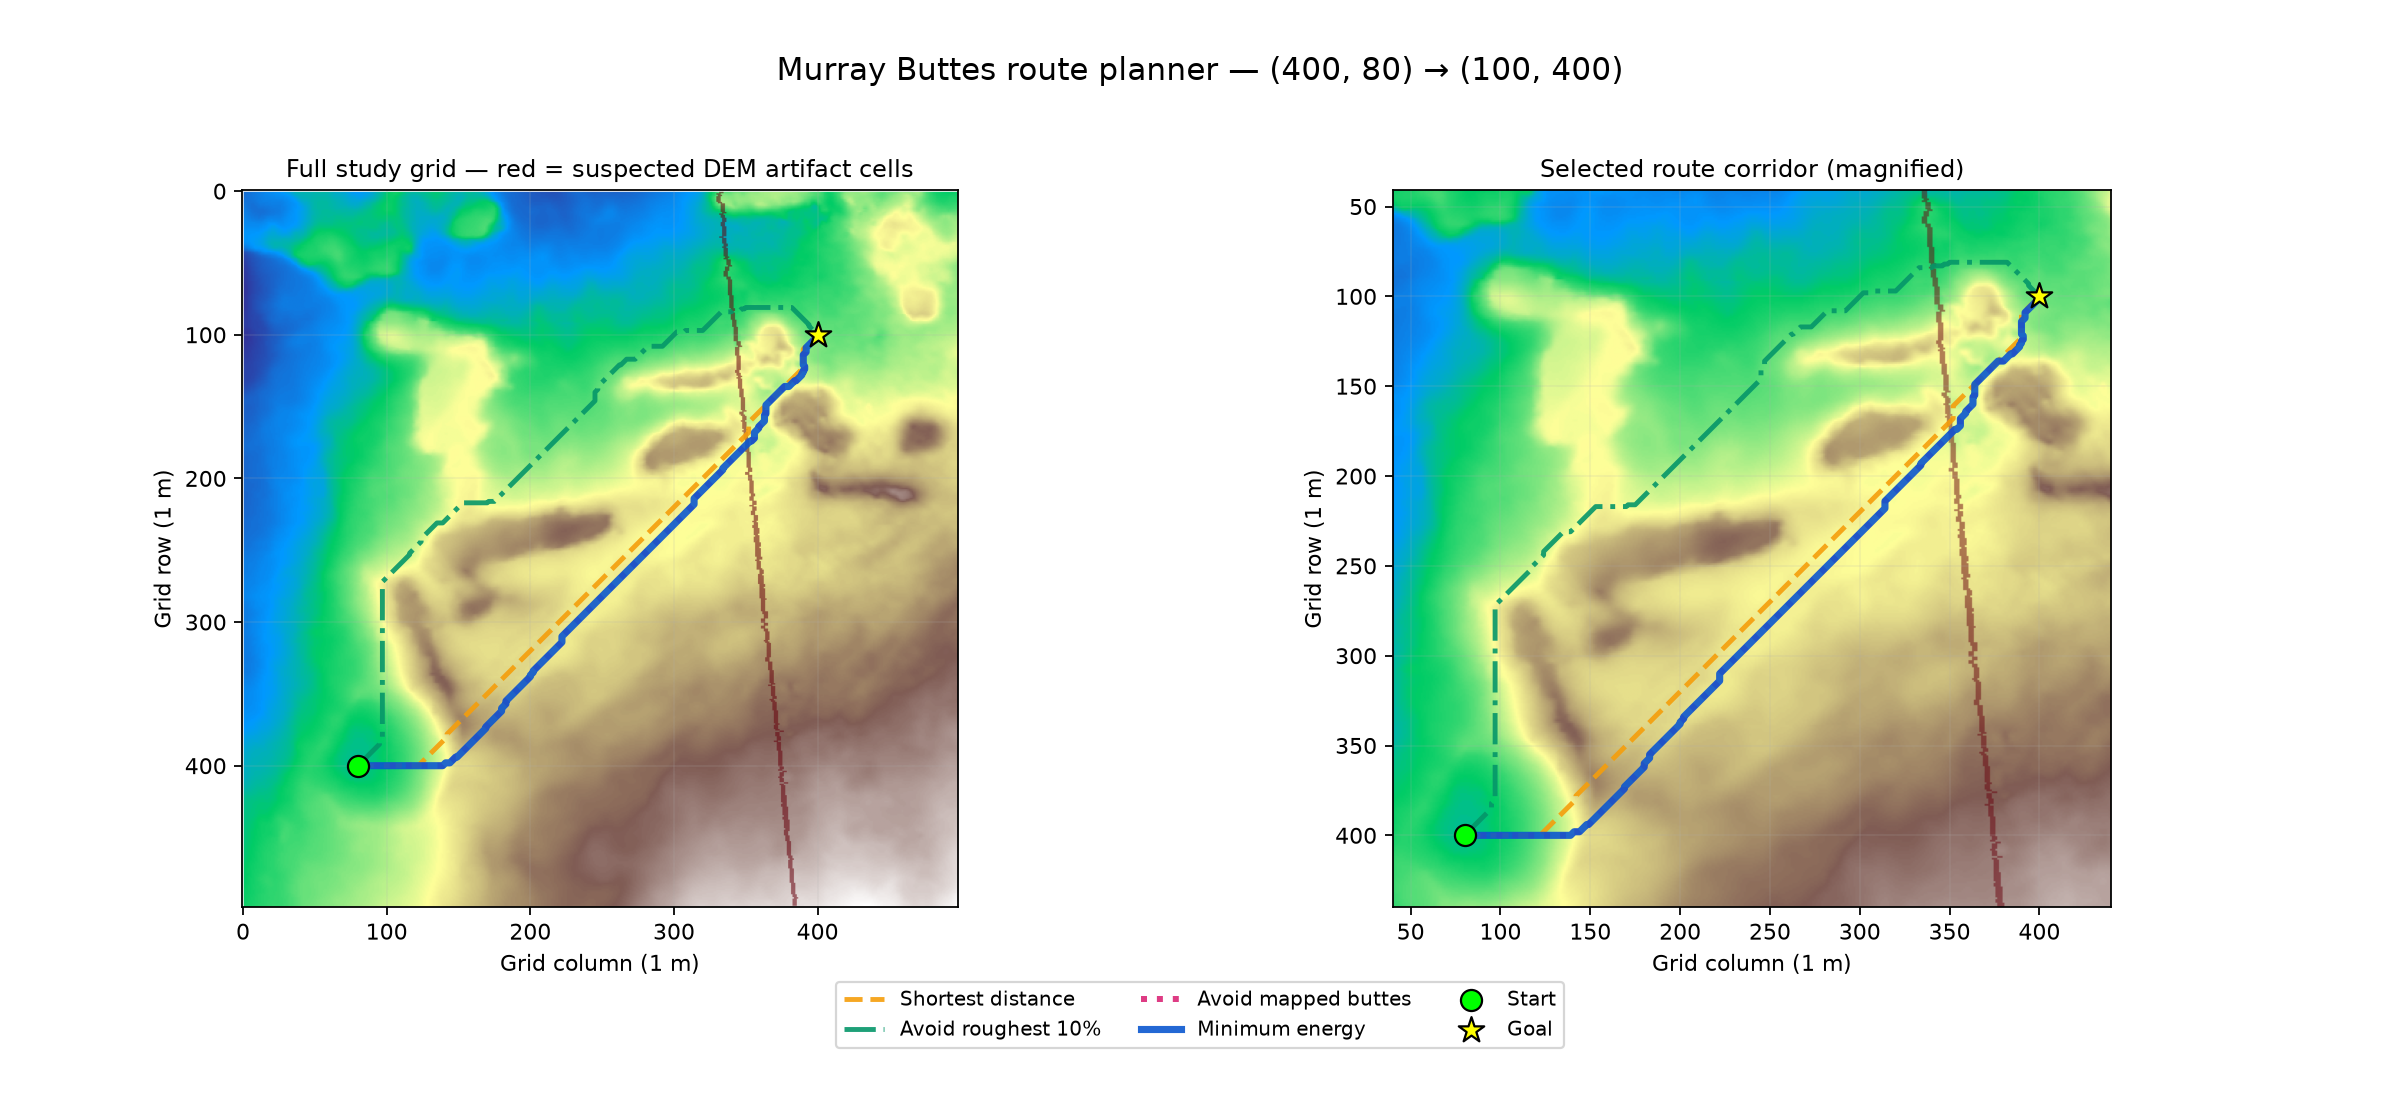

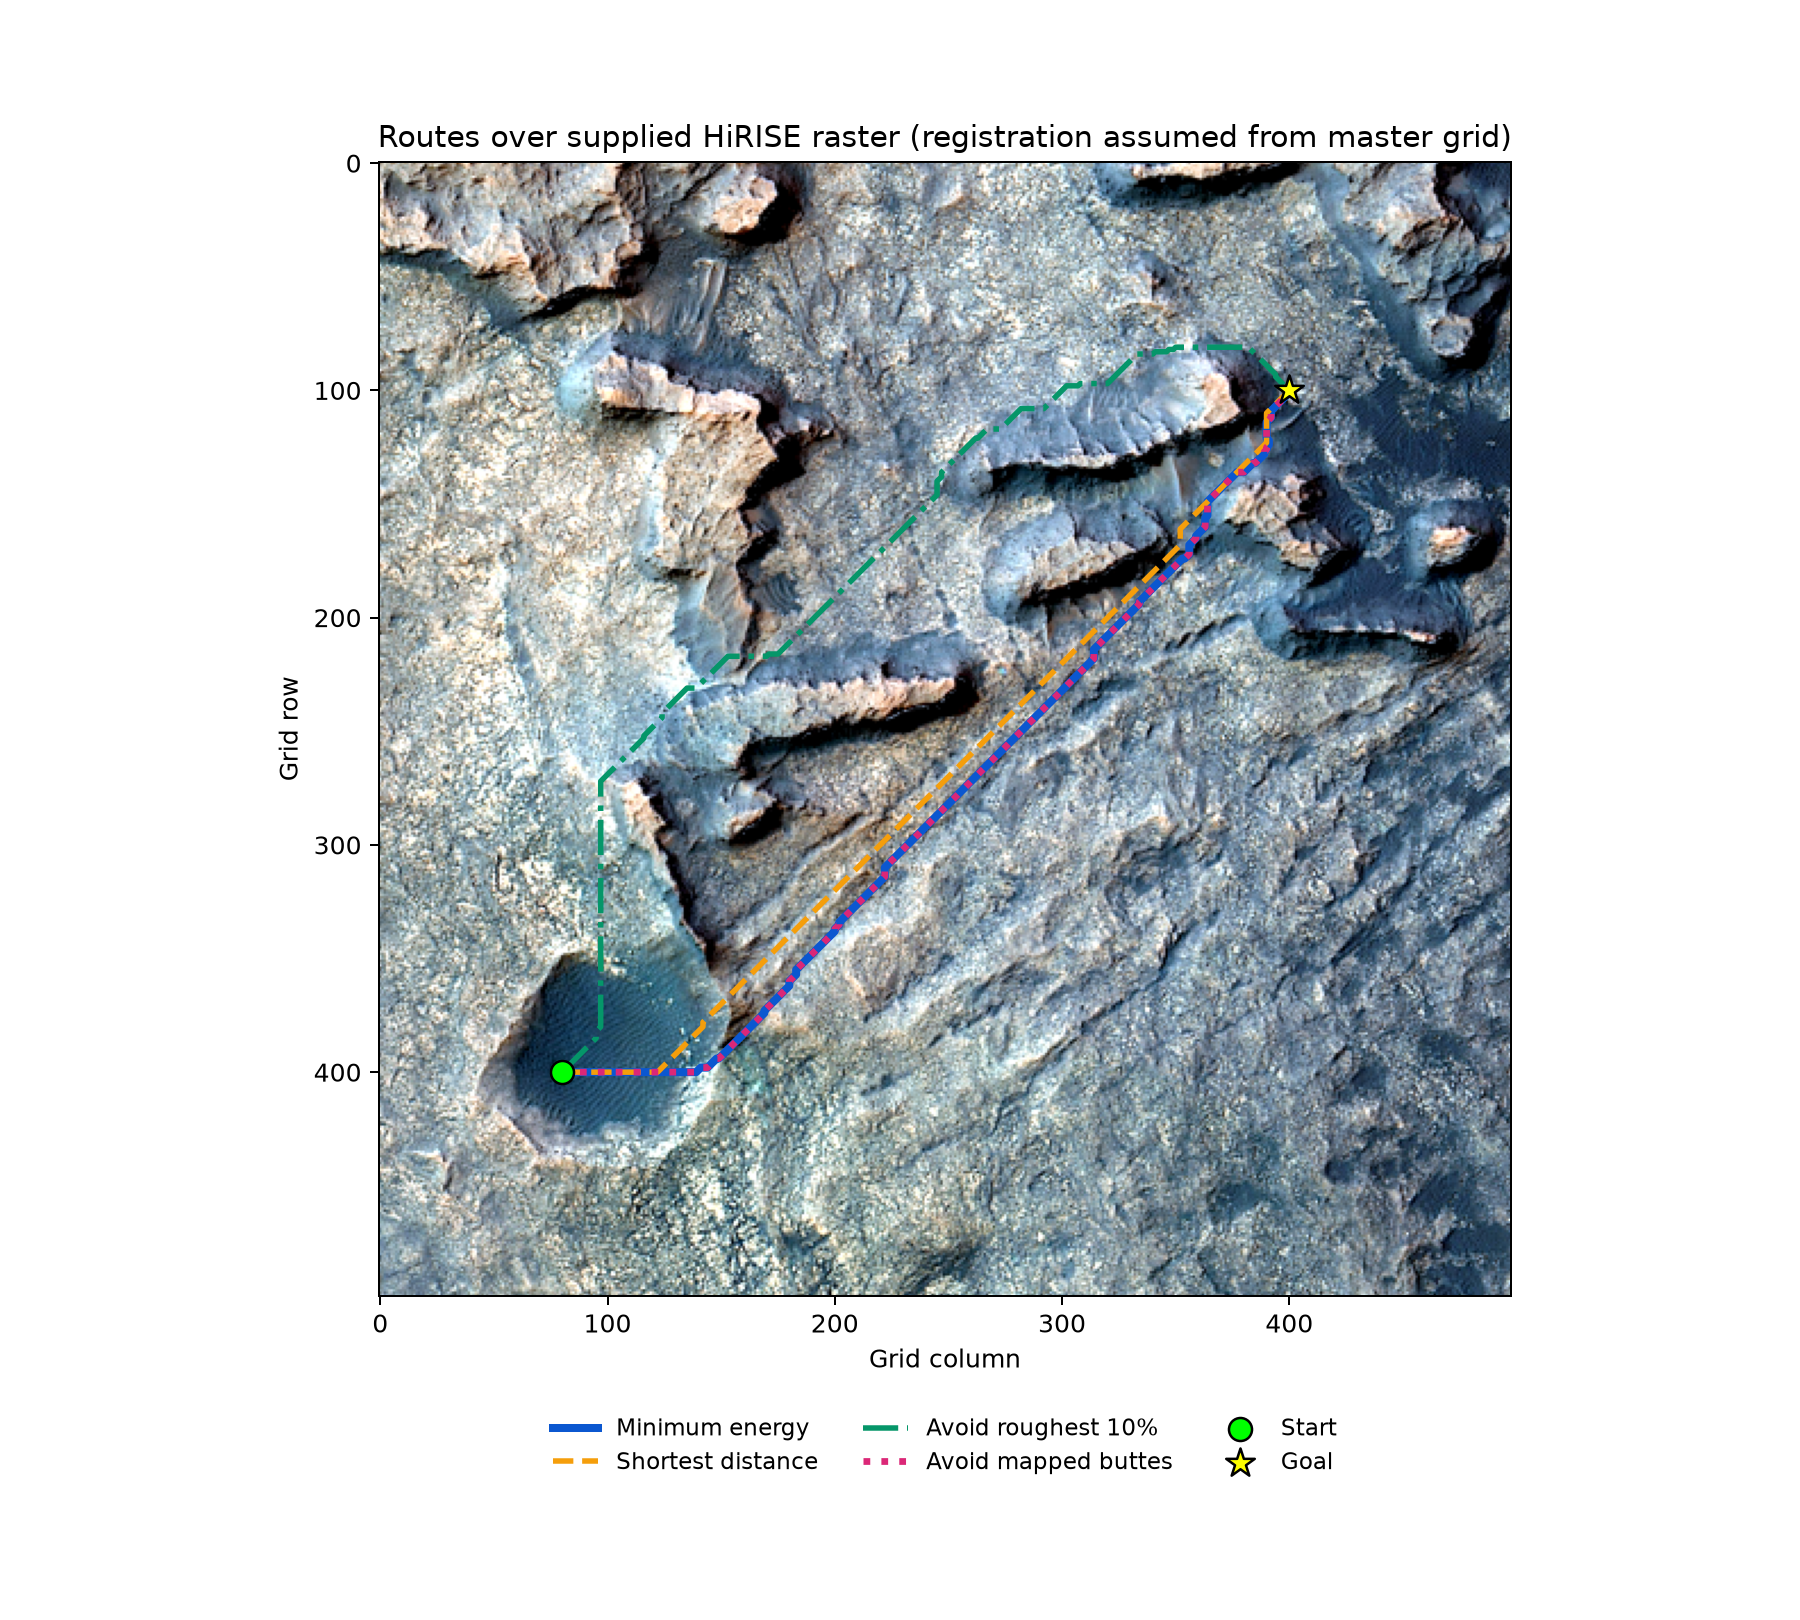

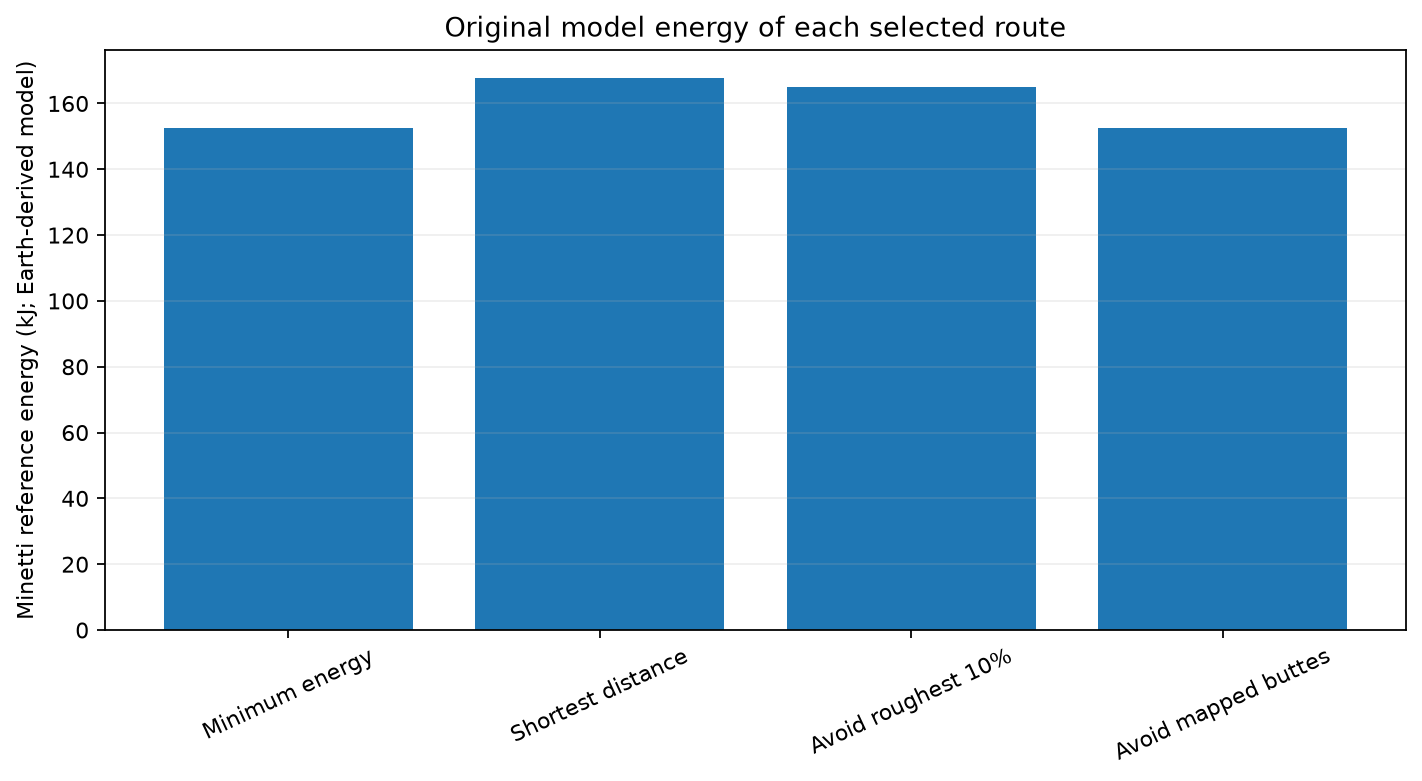

In [11]:
# Line styles are shared by the terrain and HiRISE maps, so the
# route alternatives have consistent colors in both figures.
plot_styles = {
    "Minimum energy":("#0b57d0","-",3.2),
    "Shortest distance":("#f59e0b","--",2.2),
    "Avoid roughest 10%":("#059669","-.",2.2),
    "Avoid mapped buttes":("#db2777",":",2.7),
    "Avoid roughness and buttes":("#7c3aed","--",2.3)
}

def annotate_routes(ax, zoom=False):
    # Route coordinates are (row, column); Matplotlib uses (x=col, y=row).
    if not zoom:
        ax.imshow(z,origin="upper",cmap="terrain")
        flagged = np.ma.masked_where(~artifact,artifact.astype(float))
        ax.imshow(flagged,origin="upper",cmap="Reds",vmin=0,vmax=1,alpha=0.55)
    else:
        ax.imshow(z,origin="upper",cmap="terrain")
        ax.imshow(np.ma.masked_where(~artifact,artifact.astype(float)),origin="upper",
                  cmap="Reds",vmin=0,vmax=1,alpha=.5)
    # Baseline last so it remains visible on heavily overlapping paths
    ordered = [n for n in routes if n!="Minimum energy"] + ["Minimum energy"]
    for label in ordered:
        route = np.asarray(routes[label])
        color, ls, lw = plot_styles.get(label,("black","-",2))
        ax.plot(route[:,1],route[:,0],label=label,color=color,ls=ls,lw=lw,alpha=.9)
    ax.scatter(START[1],START[0],c="lime",s=90,edgecolors="black",zorder=10,label="Start")
    ax.scatter(GOAL[1],GOAL[0],c="yellow",s=145,marker="*",edgecolors="black",zorder=10,label="Goal")
    ax.set_xlabel("Grid column (1 m)")
    ax.set_ylabel("Grid row (1 m)")
    ax.grid(alpha=.15)
    if zoom:
        pts=np.concatenate([np.asarray(p) for p in routes.values()],axis=0)
        cmin,cmax=int(pts[:,1].min()),int(pts[:,1].max())
        rmin,rmax=int(pts[:,0].min()),int(pts[:,0].max())
        margin=40  # retain the route-corridor overview, with a little extra context
        ax.set_xlim(max(0,cmin-margin),min(W-1,cmax+margin))
        ax.set_ylim(min(H-1,rmax+margin),max(0,rmin-margin))

# Main figure: original full-grid / corridor views with manually placed axes.
# Explicit positions prevent Matplotlib's automatic cropping/centering from
# leaving the second plot too close to the edge.
fig, axs = plt.subplots(1, 2, figsize=(15, 7))
annotate_routes(axs[0], zoom=False)
annotate_routes(axs[1], zoom=True)
axs[0].set_title("Full study grid — red = suspected DEM artifact cells", fontsize=11)
axs[1].set_title("Selected route corridor (magnified)", fontsize=11)

for ax in axs:
    ax.set_aspect("equal")
    ax.set_anchor("C")

axs[0].set_position([0.055, 0.19, 0.39, 0.64])
axs[1].set_position([0.535, 0.19, 0.39, 0.64])

handles, labels = axs[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center",
           bbox_to_anchor=(0.5, 0.055), ncol=3, fontsize=9)
fig.suptitle(f"Murray Buttes route planner — {START} → {GOAL}",
             fontsize=14, y=0.95)

overview_path = OUTPUT_DIR / "route_overview_and_zoom.png"
fig.savefig(overview_path, dpi=160, facecolor="white")
plt.close(fig)
if DISPLAY_OUTPUT_IMAGES:
    display(Image(filename=str(overview_path)))

# Optional imagery overlay: use georeferenced TIFF if it can be aligned safely.
hirise_status = "Not requested"
if SHOW_HIRISE_OVERLAY:
    try:
        import rasterio
        from rasterio.warp import reproject, Resampling
        from affine import Affine
        # Master x/y are assumed to match the CRS of the provided QGIS imagery.
        dx=float(np.nanmedian(np.diff(xmap,axis=1)))
        dy=float(np.nanmedian(np.diff(ymap,axis=0)))
        if not(np.isfinite(dx) and np.isfinite(dy) and dx>0 and dy<0):
            raise ValueError("Grid x/y orientation inconsistent with north-up imagery")
        target_transform=Affine(dx,0,float(xmap[0,0]-dx/2),0,dy,float(ymap[0,0]-dy/2))
        if not IMAGERY_TIF.is_file():
            raise FileNotFoundError(str(IMAGERY_TIF))
        with rasterio.open(IMAGERY_TIF) as ds:
            if ds.crs is None:
                raise ValueError("Imagery CRS is missing")
            # Assumption: master projected coordinates use this imagery CRS.
            from rasterio.transform import array_bounds
            a,b,c,d = array_bounds(H,W,target_transform)
            left,bottom,right,top=ds.bounds
            if right < a or left > c or top < b or bottom > d:
                raise ValueError("Master-grid projected extent does not overlap imagery extent")
            bands=min(3,ds.count)
            image=np.zeros((H,W,bands),dtype=np.float32)
            for idx in range(bands):
                reproject(source=rasterio.band(ds,idx+1),destination=image[:,:,idx],
                          src_transform=ds.transform,src_crs=ds.crs,
                          dst_transform=target_transform,dst_crs=ds.crs,
                          dst_nodata=np.nan,resampling=Resampling.bilinear)
        # 2/98 percentile display stretch is for visualization only.
        rendered=np.zeros_like(image)
        for idx in range(image.shape[2]):
            channel=image[:,:,idx]
            finite=np.isfinite(channel)
            if finite.any():
                lo,hi=np.percentile(channel[finite],[2,98])
                if hi>lo:
                    rendered[:,:,idx]=np.clip((channel-lo)/(hi-lo),0,1)
        if rendered.shape[2]==1:
            rendered=np.repeat(rendered,3,axis=2)
        # The image is resampled to the 1-m route grid above, so route
        # row/column indices can be plotted directly on top of it.
        fig,ax=plt.subplots(figsize=(10,9))
        ax.imshow(rendered,origin="upper")
        for label,route in routes.items():
            pts=np.asarray(route)
            color, ls, lw=plot_styles.get(label,("white","-",2))
            ax.plot(pts[:,1],pts[:,0],color=color,ls=ls,lw=lw,label=label)
        ax.scatter(START[1],START[0],c="lime",s=85,edgecolors="black",zorder=10,label="Start")
        ax.scatter(GOAL[1],GOAL[0],c="yellow",marker="*",s=145,edgecolors="black",zorder=10,label="Goal")
        ax.set_title("Routes over supplied HiRISE raster (registration assumed from master grid)")
        ax.set_xlabel("Grid column"); ax.set_ylabel("Grid row")
        ax.set_aspect("equal")
        # Keep the legend outside the photograph so the terrain stays visible.
        ax.legend(loc="upper center", bbox_to_anchor=(0.5,-0.09),
                  ncol=3, fontsize=9, frameon=False)
        fig.subplots_adjust(left=0.10,right=0.95,top=0.90,bottom=0.20)
        image_path=OUTPUT_DIR/"routes_on_hirise.png"
        fig.savefig(image_path,dpi=180,facecolor="white")
        plt.close(fig)
        if DISPLAY_OUTPUT_IMAGES: display(Image(filename=str(image_path)))
        hirise_status=f"Generated: {image_path.name} (visually confirm registration)"
    except Exception as exc:
        hirise_status=f"Unavailable: {type(exc).__name__}: {exc}"
        print("\nHiRISE imagery overlay skipped:",hirise_status)

# Reference walking-energy comparison for the same start / goal pair.
# This is an Earth-derived model score, not an EVA safety or metabolic claim.
fig,ax=plt.subplots(figsize=(9,5))
ax.bar(summary["Strategy"],summary["Minetti_reference_energy_kJ"])
ax.set_ylabel("Minetti reference energy (kJ; Earth-derived model)")
ax.set_title("Original model energy of each selected route")
ax.tick_params(axis="x",labelrotation=25)
ax.grid(axis="y",alpha=.2)
fig.tight_layout()
chart_path=OUTPUT_DIR/"route_energy_comparison.png"
fig.savefig(chart_path,dpi=160,bbox_inches="tight")
plt.close(fig)
if DISPLAY_OUTPUT_IMAGES: display(Image(filename=str(chart_path)))



## 12. Export results

Export CSV summaries and per-cell information, JSON warning records, and reconstructed elevation masks into `results/`.


In [12]:
summary.to_csv(OUTPUT_DIR/"route_summary.csv",index=False)
# The app can read this JSON to show a per-route warning banner or popup.
(OUTPUT_DIR/"route_artifact_warnings.json").write_text(
    json.dumps({"routes":route_warnings},indent=2),encoding="utf-8")
pd.DataFrame([{k:v for k,v in w.items() if k!="crossing_cells"}
              for w in route_warnings]).to_csv(
                  OUTPUT_DIR/"route_artifact_warnings.csv",index=False)
# Standalone overlay on the same row/column grid; 1 = interpolated elevation.
pd.DataFrame({"row":np.repeat(np.arange(H),W),
              "col":np.tile(np.arange(W),H),
              "artifact_suspected":artifact.ravel(),
              "elevation_reconstructed":reconstructed.ravel(),
              "elevation_used_m":z.ravel()}).to_csv(
                  OUTPUT_DIR/"reconstruction_audit_grid.csv",index=False)
# Lightweight NumPy binary for integration; original CSV and TIFF unchanged.
np.savez_compressed(OUTPUT_DIR/"reconstructed_elevation_and_masks.npz",
                    elevation_m=z, artifact_suspected=artifact,
                    elevation_reconstructed=reconstructed)
pd.DataFrame(route_cells).to_csv(OUTPUT_DIR/"route_coordinates_and_cell_attributes.csv",index=False)
if SAVE_STEP_LEVEL_TABLE:
    pd.DataFrame(route_steps).to_csv(OUTPUT_DIR/"route_movement_energy.csv",index=False)
if RUN_MONTE_CARLO:
    mc_samples.to_csv(OUTPUT_DIR/"monte_carlo_samples.csv",index=False)
    mc_summary.to_csv(OUTPUT_DIR/"monte_carlo_summary.csv",index=False)



## 13. Internal checks

Record simple consistency checks for the inputs, reconstructed cells and selected routes.


In [13]:
validation = pd.DataFrame([
    {"Check":"Master grid ordering verified","Passed":True},
    {"Check":"Start/destination are valid and unflagged","Passed":bool(usable[START] and usable[GOAL] and not artifact[START] and not artifact[GOAL])},
    {"Check":"All crossed flagged cells have reconstructed elevations","Passed":all(np.all(
        ~artifact[np.asarray(p)[:,0],np.asarray(p)[:,1]] | reconstructed[np.asarray(p)[:,0],np.asarray(p)[:,1]])
        for p in routes.values())},
    {"Check":"All routes avoid invalid DEM cells","Passed":all(usable[np.asarray(p)[:,0],np.asarray(p)[:,1]].all() for p in routes.values())},
    {"Check":"All selected edges within nominal grade limit","Passed":all(np.all(np.abs((z[d[:,0],d[:,1]]-z[s[:,0],s[:,1]])/L)<=MAX_ABS_GRADE+1e-10)
          for s,d,L in geometries.values())},
    {"Check":"Minimum-energy route found","Passed":"Minimum energy" in routes},
])
validation.to_csv(OUTPUT_DIR/"internal_model_checks.csv",index=False)



## Interpreting the results

- `route_summary.csv` compares feasible strategies. If a route does not exist under its restrictions, it is recorded as infeasible.
- `route_artifact_warnings.json` / `.csv` contain per-route warnings for crossings of interpolated terrain. Estimated elevation is not verified passability.
- `route_coordinates_and_cell_attributes.csv` and `route_movement_energy.csv` provide finer route details for analysis or integration.
- `reconstructed_elevation_and_masks.npz` and `reconstruction_audit_grid.csv` document where interpolation was applied.
- `monte_carlo_summary.csv` and `monte_carlo_samples.csv` report fixed-route sensitivity to hypothetical DEM errors, when enabled.
- `internal_model_checks.csv` and `model_settings_and_limitations.json` document basic checks and modelling assumptions.
